In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("Libraries imported successfully!")

Libraries imported successfully!


In [2]:
url = "https://github.com/Naseerahmadtaraki/RetailSotreDataset/raw/refs/heads/main/retail_sales_dataset.csv"

df = pd.read_csv(url)

print("Retail dataset loaded successfully!")

Retail dataset loaded successfully!


In [3]:
df.head()

,Transaction ID,Date,Customer ID,Gender,Age,Product Category,Quantity,Price per Unit,Total Amount
0,1,2023-11-24,CUST001,Male,34,Beauty,3,50,150
1,2,2023-02-27,CUST002,Female,26,Clothing,2,500,1000
2,3,2023-01-13,CUST003,Male,50,Electronics,1,30,30
3,4,2023-05-21,CUST004,Male,37,Clothing,1,500,500
4,5,2023-05-06,CUST005,Male,30,Beauty,2,50,100


In [4]:
df.shape
df.columns
df.info()
df.describe()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 9 columns):
 #   Column            Non-Null Count  Dtype 
---  ------            --------------  ----- 
 0   Transaction ID    1000 non-null   int64 
 1   Date              1000 non-null   object
 2   Customer ID       1000 non-null   object
 3   Gender            1000 non-null   object
 4   Age               1000 non-null   int64 
 5   Product Category  1000 non-null   object
 6   Quantity          1000 non-null   int64 
 7   Price per Unit    1000 non-null   int64 
 8   Total Amount      1000 non-null   int64 
dtypes: int64(5), object(4)
memory usage: 70.4+ KB


,Transaction ID,Age,Quantity,Price per Unit,Total Amount
count,1000.000000,1000.00000,1000.000000,1000.000000,1000.000000
mean,500.500000,41.39200,2.514000,179.890000,456.000000
std,288.819436,13.68143,1.132734,189.681356,559.997632
min,1.000000,18.00000,1.000000,25.000000,25.000000
25%,250.750000,29.00000,1.000000,30.000000,60.000000
50%,500.500000,42.00000,3.000000,50.000000,135.000000
75%,750.250000,53.00000,4.000000,300.000000,900.000000
max,1000.000000,64.00000,4.000000,500.000000,2000.000000


In [5]:
print("Missing Values:")
print(df.isnull().sum())

print("Total Missing Values:")
print(df.isnull().sum().sum())

Missing Values:
Transaction ID      0
Date                0
Customer ID         0
Gender              0
Age                 0
Product Category    0
Quantity            0
Price per Unit      0
Total Amount        0
dtype: int64
Total Missing Values:
0


In [6]:
print("Duplicate Records:")
print(df.duplicated().sum())

Duplicate Records:
0


In [7]:
df_clean = df.drop_duplicates().copy()

print("Original Shape:", df.shape)
print("Cleaned Shape:", df_clean.shape)

Original Shape: (1000, 9)
Cleaned Shape: (1000, 9)


In [8]:
df_clean['Date'] = pd.to_datetime(
    df_clean['Date'],
    errors='coerce'
)

print(df_clean['Date'].dtype)

datetime64[ns]


In [9]:
df_clean.info()

df_clean.head()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 9 columns):
 #   Column            Non-Null Count  Dtype         
---  ------            --------------  -----         
 0   Transaction ID    1000 non-null   int64         
 1   Date              1000 non-null   datetime64[ns]
 2   Customer ID       1000 non-null   object        
 3   Gender            1000 non-null   object        
 4   Age               1000 non-null   int64         
 5   Product Category  1000 non-null   object        
 6   Quantity          1000 non-null   int64         
 7   Price per Unit    1000 non-null   int64         
 8   Total Amount      1000 non-null   int64         
dtypes: datetime64[ns](1), int64(5), object(3)
memory usage: 70.4+ KB


,Transaction ID,Date,Customer ID,Gender,Age,Product Category,Quantity,Price per Unit,Total Amount
0,1,2023-11-24,CUST001,Male,34,Beauty,3,50,150
1,2,2023-02-27,CUST002,Female,26,Clothing,2,500,1000
2,3,2023-01-13,CUST003,Male,50,Electronics,1,30,30
3,4,2023-05-21,CUST004,Male,37,Clothing,1,500,500
4,5,2023-05-06,CUST005,Male,30,Beauty,2,50,100


In [10]:
# Check missing values
print("Missing Values:")
print(df_clean.isnull().sum())

print("\nTotal Missing Values:")
print(df_clean.isnull().sum().sum())

# Check duplicate records
print("\nDuplicate Records:")
print(df_clean.duplicated().sum())

# Check cleaned dataset size
print("\nCleaned Dataset Shape:")
print(df_clean.shape)

# Display first five rows
df_clean.head()

Missing Values:
Transaction ID      0
Date                0
Customer ID         0
Gender              0
Age                 0
Product Category    0
Quantity            0
Price per Unit      0
Total Amount        0
dtype: int64

Total Missing Values:
0

Duplicate Records:
0

Cleaned Dataset Shape:
(1000, 9)


,Transaction ID,Date,Customer ID,Gender,Age,Product Category,Quantity,Price per Unit,Total Amount
0,1,2023-11-24,CUST001,Male,34,Beauty,3,50,150
1,2,2023-02-27,CUST002,Female,26,Clothing,2,500,1000
2,3,2023-01-13,CUST003,Male,50,Electronics,1,30,30
3,4,2023-05-21,CUST004,Male,37,Clothing,1,500,500
4,5,2023-05-06,CUST005,Male,30,Beauty,2,50,100


In [11]:
# Total Sales
print("Total Sales:", df_clean['Total Amount'].sum())

# Total Transactions
print("Total Transactions:", df_clean['Transaction ID'].nunique())

# Average Sales
print("Average Sales:", df_clean['Total Amount'].mean())

# Best Selling Category
print("\nSales by Product Category:")
print(df_clean.groupby('Product Category')['Total Amount'].sum())

Total Sales: 456000
Total Transactions: 1000
Average Sales: 456.0

Sales by Product Category:
Product Category
Beauty         143515
Clothing       155580
Electronics    156905
Name: Total Amount, dtype: int64


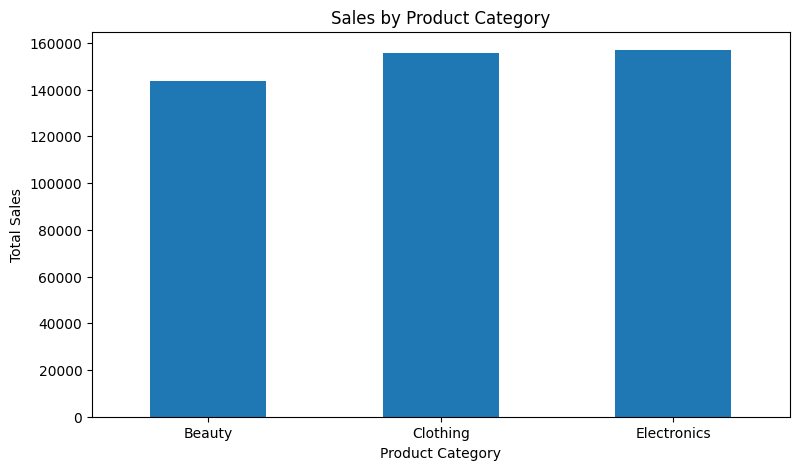

In [12]:
category_sales = df_clean.groupby(
    'Product Category'
)['Total Amount'].sum()

plt.figure(figsize=(9,5))

category_sales.plot(kind='bar')

plt.title('Sales by Product Category')
plt.xlabel('Product Category')
plt.ylabel('Total Sales')
plt.xticks(rotation=0)

plt.show()

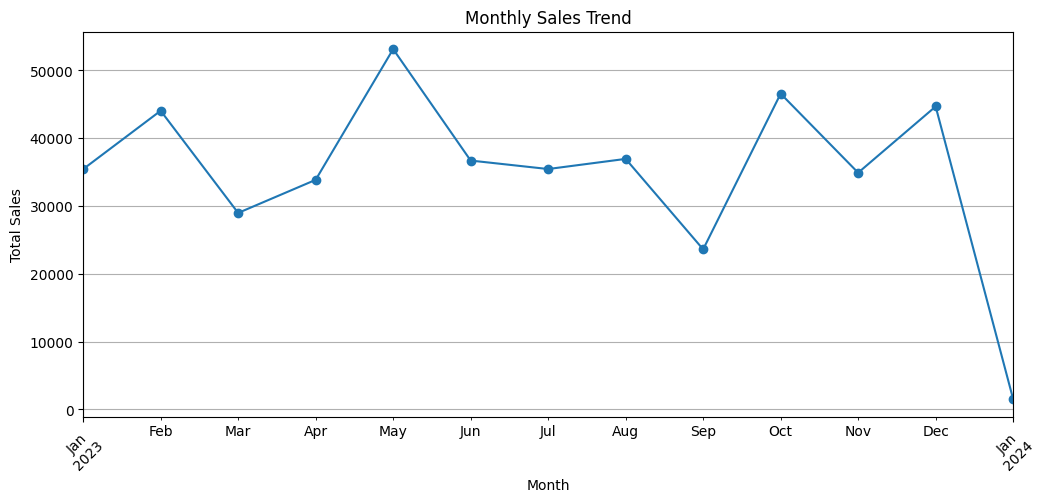

In [14]:
df_clean['Month'] = df_clean['Date'].dt.to_period('M')

monthly_sales = df_clean.groupby(
    'Month'
)['Total Amount'].sum()

plt.figure(figsize=(12,5))

monthly_sales.plot(kind='line', marker='o')

plt.title('Monthly Sales Trend')
plt.xlabel('Month')
plt.ylabel('Total Sales')
plt.xticks(rotation=45)

plt.grid(True)
plt.show()

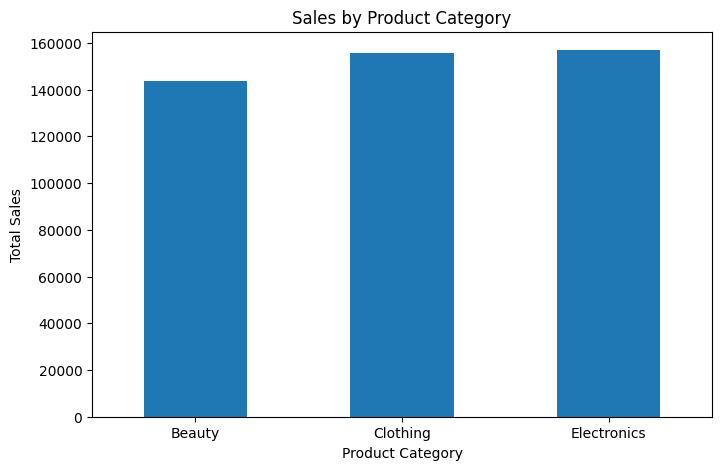

In [20]:
category_sales = df_clean.groupby(
    'Product Category'
)['Total Amount'].sum()

plt.figure(figsize=(8,5))
category_sales.plot(kind='bar')

plt.title('Sales by Product Category')
plt.xlabel('Product Category')
plt.ylabel('Total Sales')
plt.xticks(rotation=0)

plt.savefig('category_sales.png',
             dpi=300, bbox_inches='tight')

plt.show()

In [21]:
from google.colab import files
files.download('category_sales.png')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

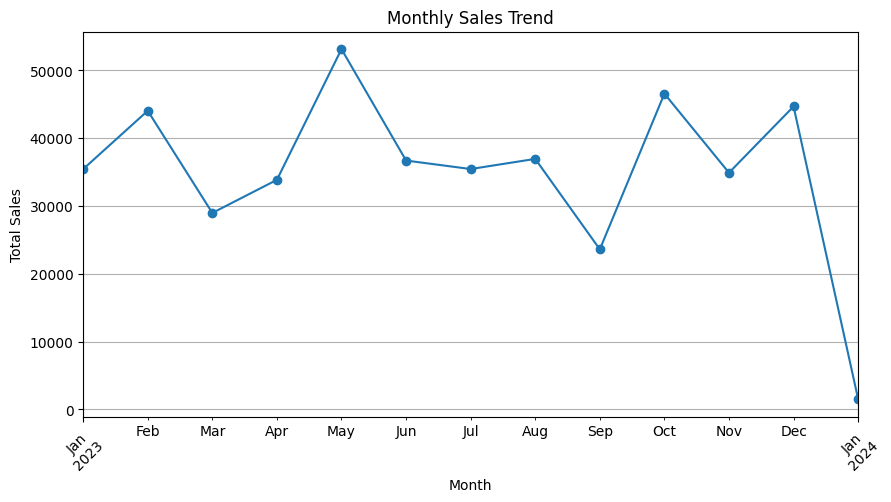

In [22]:
monthly_sales = df_clean.groupby(
    df_clean['Date'].dt.to_period('M')
)['Total Amount'].sum()

plt.figure(figsize=(10,5))
monthly_sales.plot(kind='line', marker='o')

plt.title('Monthly Sales Trend')
plt.xlabel('Month')
plt.ylabel('Total Sales')
plt.xticks(rotation=45)
plt.grid(True)

plt.savefig(
    'monthly_sales.png',
    dpi=300,
    bbox_inches='tight'
)

plt.show()

In [23]:
from google.colab import files
files.download('monthly_sales.png')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [24]:
import zipfile
from google.colab import files

images = [
    'gender_sales.png',
    'category_sales.png',
    'monthly_sales.png'
]

with zipfile.ZipFile('Retail_EDA_Graphs.zip', 'w') as z:
    for img in images:
        z.write(img)

files.download('Retail_EDA_Graphs.zip')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [25]:
!pip install reportlab -q

import os
import pandas as pd
from reportlab.lib.pagesizes import A4
from reportlab.platypus import (
    SimpleDocTemplate, Paragraph, Spacer,
    Table, TableStyle, Image, PageBreak
)
from reportlab.lib.styles import getSampleStyleSheet
from reportlab.lib import colors

# Create PDF
pdf_name = "Retail_EDA_Final_Report.pdf"

doc = SimpleDocTemplate(pdf_name, pagesize=A4)
styles = getSampleStyleSheet()
story = []

# Title
story.append(Paragraph(
    "REAL-WORLD RETAIL DATA ANALYSIS",
    styles['Title']
))
story.append(Spacer(1, 20))

story.append(Paragraph("1. Introduction", styles['Heading1']))
story.append(Paragraph(
    "This project explores retail transaction data to identify "
    "sales patterns, customer behaviour and product performance "
    "using Exploratory Data Analysis (EDA).",
    styles['BodyText']
))
story.append(Spacer(1, 15))

# Dataset description
story.append(Paragraph("2. Dataset Description", styles['Heading1']))

data = [
    ["Parameter", "Value"],
    ["Total Records", str(len(df_clean))],
    ["Total Columns", str(len(df_clean.columns))],
    ["Total Sales", f"Rs. {df_clean['Total Amount'].sum():,.2f}"],
    ["Total Transactions",
     str(df_clean['Transaction ID'].nunique())],
    ["Average Sales",
     f"Rs. {df_clean['Total Amount'].mean():,.2f}"]
]

table = Table(data, colWidths=[200, 200])
table.setStyle(TableStyle([
    ('BACKGROUND', (0,0), (-1,0), colors.lightblue),
    ('GRID', (0,0), (-1,-1), 1, colors.grey),
    ('PADDING', (0,0), (-1,-1), 8)
]))
story.append(table)
story.append(Spacer(1, 15))

# Data cleaning
story.append(Paragraph("3. Data Cleaning", styles['Heading1']))
story.append(Paragraph(
    "The dataset was checked for missing values and duplicate "
    "records. The date column was converted into datetime format. "
    "Duplicate records were removed.",
    styles['BodyText']
))
story.append(Spacer(1, 15))

# Category analysis
story.append(Paragraph("4. Product Category Analysis", styles['Heading1']))

category_sales = df_clean.groupby(
    'Product Category'
)['Total Amount'].sum().sort_values(ascending=False)

cat_data = [["Product Category", "Total Sales"]]
for name, value in category_sales.items():
    cat_data.append([str(name), f"Rs. {value:,.2f}"])

cat_table = Table(cat_data, colWidths=[200, 200])
cat_table.setStyle(TableStyle([
    ('BACKGROUND', (0,0), (-1,0), colors.lightblue),
    ('GRID', (0,0), (-1,-1), 1, colors.grey),
    ('PADDING', (0,0), (-1,-1), 8)
]))
story.append(cat_table)
story.append(Spacer(1, 15))

# Visualizations
story.append(Paragraph("5. Data Visualizations", styles['Heading1']))

for filename, caption in [
    ('category_sales.png', 'Category-wise Sales'),
    ('gender_sales.png', 'Gender-wise Sales Distribution'),
    ('monthly_sales.png', 'Monthly Sales Trend')
]:
    if os.path.exists(filename):
        story.append(Paragraph(caption, styles['Heading2']))
        story.append(Image(filename, width=420, height=230))
        story.append(Spacer(1, 15))

# Findings
story.append(Paragraph("6. Key Findings", styles['Heading1']))
story.append(Paragraph(
    "1. Total recorded sales amounted to Rs. "
    f"{df_clean['Total Amount'].sum():,.2f}.<br/>"
    "2. Electronics recorded the highest category sales in "
    "the observed dataset.<br/>"
    "3. Sales performance varied across months.<br/>"
    "4. Customer gender and product categories were explored.",
    styles['BodyText']
))
story.append(Spacer(1, 15))

# Conclusion
story.append(Paragraph("7. Conclusion", styles['Heading1']))
story.append(Paragraph(
    "This EDA project provided insights into retail sales, "
    "product categories and customer purchasing patterns. "
    "The visualizations and statistical summaries help "
    "understand business performance and support data-driven "
    "decision-making.",
    styles['BodyText']
))

doc.build(story)

print("PDF Report Created Successfully!")

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
gradio 6.31.0 requires pillow<13.0,>=8.0, but you have pillow 13.0.0 which is incompatible.
PDF Report Created Successfully!


In [26]:
from google.colab import files
files.download('Retail_EDA_Final_Report.pdf')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

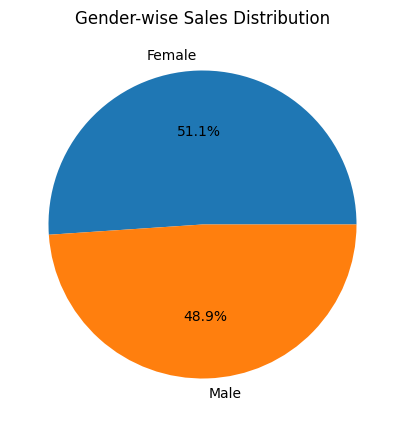

In [13]:
gender_sales = df_clean.groupby(
    'Gender'
)['Total Amount'].sum()

plt.figure(figsize=(7,5))

gender_sales.plot(kind='pie', autopct='%1.1f%%')

plt.title('Gender-wise Sales Distribution')
plt.ylabel('')

plt.show()

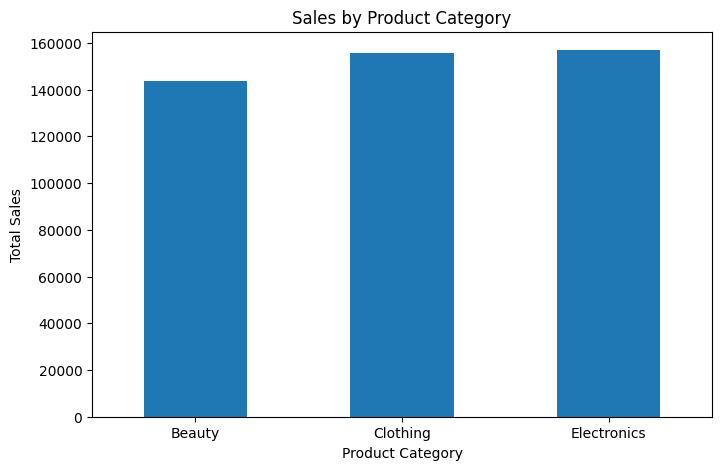

In [15]:
category_sales = df_clean.groupby(
    'Product Category'
)['Total Amount'].sum()

plt.figure(figsize=(8,5))

category_sales.plot(kind='bar')

plt.title('Sales by Product Category')
plt.xlabel('Product Category')
plt.ylabel('Total Sales')

plt.xticks(rotation=0)
plt.show()

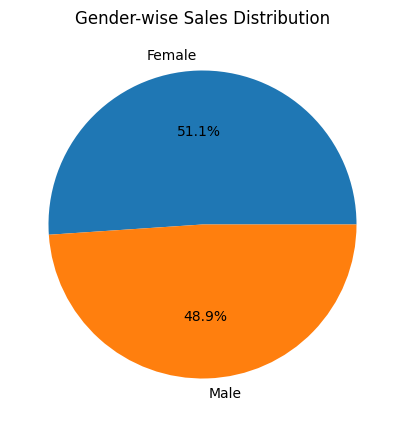

In [16]:
gender_sales = df_clean.groupby(
    'Gender'
)['Total Amount'].sum()

plt.figure(figsize=(7,5))

gender_sales.plot(
    kind='pie',
    autopct='%1.1f%%'
)

plt.title('Gender-wise Sales Distribution')
plt.ylabel('')

plt.show()

In [17]:
plt.savefig('sales_chart.png')

<Figure size 640x480 with 0 Axes>

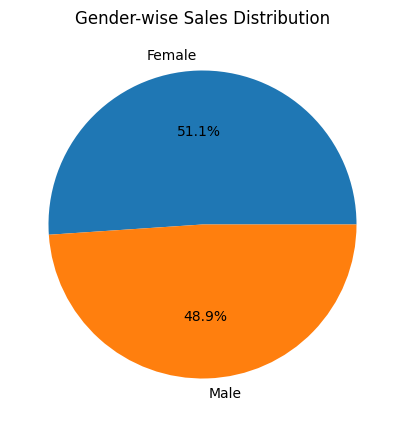

In [18]:
gender_sales = df_clean.groupby(
    'Gender'
)['Total Amount'].sum()

plt.figure(figsize=(7,5))

gender_sales.plot(
    kind='pie',
    autopct='%1.1f%%'
)

plt.title('Gender-wise Sales Distribution')
plt.ylabel('')

plt.savefig(
    'gender_sales.png',
    bbox_inches='tight'
)

plt.show()

In [19]:
from google.colab import files
files.download('gender_sales.png')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>